<a href="https://colab.research.google.com/github/Layal06-gh/IT326-Airline-Satisfaction/blob/main/phases/Phase3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IT326 – Airline Passenger Satisfaction
## Final Report

**Group Members:**
* Layal Alkthiry
* Zahra Alkubaish
* Dania Alduailij
* Dana Alwafi

# [1] Problem

Air travel has become a highly competitive service industry, where a passenger's experience — from booking to baggage claim — directly affects airline loyalty, repeat business, and revenue. The core problem we address is understanding and predicting airline passenger satisfaction using the feedback passengers give on multiple service dimensions (online boarding, inflight wifi, seat comfort, cleanliness, delays, etc.).

Specifically, we want to answer two questions:

1. Given a passenger's travel and service-rating profile, will they be satisfied or neutral/dissatisfied? (classification).

2. What natural groups of passengers exist based on their service ratings and travel characteristics, even when we ignore the satisfaction label? (clustering).

Solving this is important because airlines operate on thin margins and high fixed costs — being able to flag dissatisfied passengers before they churn, and being able to design targeted service packages for distinct passenger segments, turns survey data into actionable business decisions. It also helps prioritise which service dimensions (wifi vs food vs legroom) give the biggest lift in satisfaction per dollar spent.

# [2] Data Mining Task

We formalize the problem as two complementary data mining tasks on the same preprocessed dataset (123,310 records × 22 numeric features):

1. Classification (supervised)

 Task: Predict the class attribute satisfaction, which is binary:
 0 → neutral or dissatisfied (69,241 records, ~56.2%)
 1 → satisfied (54,069 records, ~43.8%)
 Algorithm: Decision Tree (CART), evaluated with two attribute-selection measures — Gini index and Information Gain (Entropy) — using DecisionTreeClassifier from sklearn.tree.
 Partitions: 90/10, 80/20, 70/30 train–test splits with stratification on satisfaction.
 Why a tree: trees produce human-readable rules (e.g. "if Online boarding is low and Type of Travel = Personal → neutral or dissatisfied"), which directly tell the airline which services to fix.

 2. Clustering (unsupervised)

 Task: Partition passengers into $K$ groups based on the 22 features without using the satisfaction label, so that passengers inside a cluster are similar and passengers across clusters are different.
 Algorithm: K-means from sklearn.cluster.KMeans, with $K \in \{3,4,5\}$ chosen from the Elbow curve.
 Validation: Silhouette score (cohesion + separation) and Total Within-Cluster Sum of Squares (WSS / Inertia).
 Why K-means: it scales well to 123k rows, all features are numeric and Min–Max normalised (so Euclidean distance is meaningful), and centroids give interpretable "average passenger" profiles per cluster.

# [3] Data

The dataset used in this project is the **Airline Passenger Satisfaction** dataset from Kaggle [2]. It contains survey results of airline passengers, including their personal and travel information and their ratings (0–5) of 14 service dimensions. The class label is `satisfaction`, with two classes: *neutral or dissatisfied* and *satisfied*.

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

raw_url = 'https://github.com/Layal06-gh/IT326-Airline-Satisfaction/raw/refs/heads/main/Dataset/Raw_dataset.csv'
df_raw = pd.read_csv(raw_url)

print("Number of attributes:", df_raw.shape[1])
print("Number of objects:", df_raw.shape[0])
print("Class label:", df_raw.columns[-1])
print("\nAttribute types:")
print(df_raw.dtypes.to_frame(name='Data Type'))

Number of attributes: 25
Number of objects: 129880
Class label: satisfaction

Attribute types:
                                  Data Type
Unnamed: 0                            int64
id                                    int64
Gender                               object
Customer Type                        object
Age                                   int64
Type of Travel                       object
Class                                object
Flight Distance                       int64
Inflight wifi service                 int64
Departure/Arrival time convenient     int64
Ease of Online booking                int64
Gate location                         int64
Food and drink                        int64
Online boarding                       int64
Seat comfort                          int64
Inflight entertainment                int64
On-board service                      int64
Leg room service                      int64
Baggage handling                      int64
Checkin service          

## 3.1 Data Analysis

### 1. Statistical Summary

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_raw.describe()

,Unnamed: 0,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129487.000000
mean,44158.700000,64940.500000,39.427957,1190.316392,2.728696,3.057599,2.756876,2.976925,3.204774,3.252633,3.441361,3.358077,3.383023,3.350878,3.632114,3.306267,3.642193,3.286326,14.713713,15.091129
std,31207.377062,37493.270818,15.119360,997.452477,1.329340,1.526741,1.401740,1.278520,1.329933,1.350719,1.319289,1.334049,1.287099,1.316252,1.180025,1.266185,1.176669,1.313682,38.071126,38.465650
min,0.000000,1.000000,7.000000,31.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,16234.750000,32470.750000,27.000000,414.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,38963.500000,64940.500000,40.000000,844.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,4.000000,3.000000,0.000000,0.000000
75%,71433.250000,97410.250000,51.000000,1744.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,4.000000,5.000000,4.000000,5.000000,4.000000,12.000000,13.000000
max,103903.000000,129880.000000,85.000000,4983.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1592.000000,1584.000000


**Description of the statistical summary (five-number summary):**

| Attribute | Min | Q1 | Median | Q3 | Max | Mean |
|---|---|---|---|---|---|---|
| Age | 7 | 27 | 40 | 51 | 85 | 39.4 |
| Flight Distance | 31 | 414 | 844 | 1,744 | 4,983 | 1,190.3 |
| Departure Delay in Minutes | 0 | 0 | 0 | 12 | 1,592 | 14.7 |
| Arrival Delay in Minutes | 0 | 0 | 0 | 13 | 1,584 | 15.1 |

- **Age:** The mean (39.4) is almost equal to the median (40), so Age is roughly symmetric. Half of the passengers are between 27 and 51 years old.
- **Flight Distance:** The mean (1,190) is much larger than the median (844), which shows the attribute is right-skewed: a smaller number of long-haul flights pull the mean up. The range is very wide (31 to 4,983 miles).
- **Departure and Arrival Delay:** Q1 and the median are both 0, which means at least half of the flights had no delay. However, the maximum (about 1,590 minutes) is far above Q3 (12–13 minutes), so these attributes are extremely skewed and contain extreme outliers. The count of Arrival Delay is 129,487 instead of 129,880, which shows it has 393 missing values.
- **Service ratings (14 attributes):** All ratings are on a 0–5 scale, with medians of 3 or 4 and most values between 2 and 5. The lowest average ratings are *Inflight wifi service* (2.73) and *Ease of Online booking* (2.76), while the highest are *Inflight service* (3.64) and *Baggage handling* (3.63).
- **Unnamed: 0 and id:** These are only row/passenger identifiers, so their statistics have no meaning; they are removed during preprocessing.

**How this helped preprocessing:** The attributes have very different scales (ratings 0–5, Age up to 85, Flight Distance up to about 5,000), so **normalization** is needed. The strong skew and extreme values in the delay attributes show that **outlier handling** is needed, and the missing Arrival Delay values must be **imputed**.

### 2. Missing Values Analysis


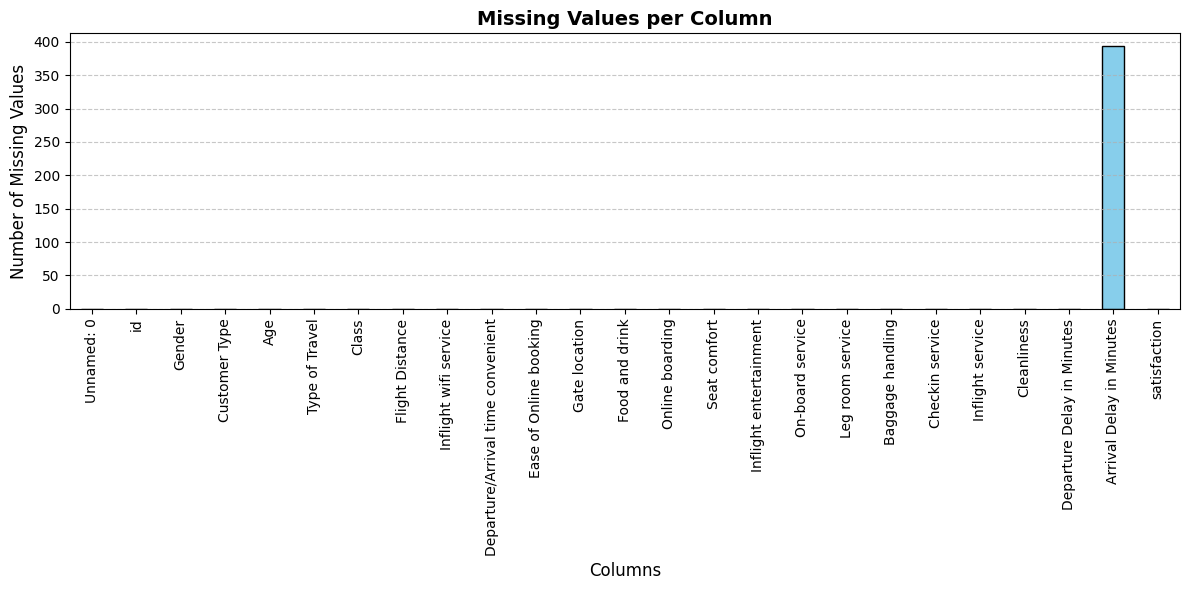

In [47]:
import matplotlib.pyplot as plt

missing_vals = df_raw.isnull().sum()

plt.figure(figsize=(12, 6))
missing_vals.plot(kind='bar', color='skyblue', edgecolor='black')

plt.title('Missing Values per Column', fontsize=14, fontweight='bold')
plt.xlabel('Columns', fontsize=12)
plt.ylabel('Number of Missing Values', fontsize=12)

plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

The missing values analysis reveals that the dataset is clean and complete across almost all attributes, except for 'Arrival Delay in Minutes', which contains exactly 393 missing values.

Identifying these missing values directly justifies the necessity of applying an imputation technique (such as median imputation or mean imputation) during the Data Preprocessing stage to handle these 393 missing records before training classification models.


### 3. Boxplots

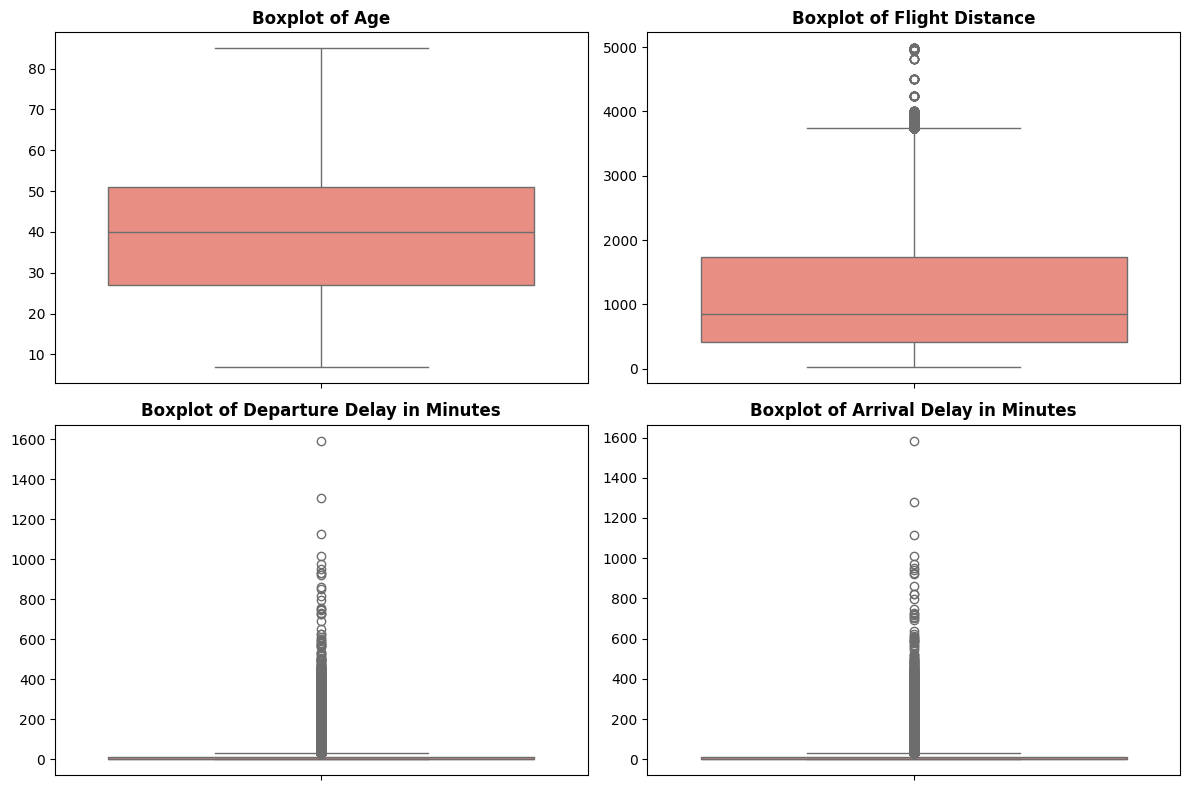

In [48]:
main_numeric_cols = ['Age', 'Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']

plt.figure(figsize=(12, 8))
for i, col in enumerate(main_numeric_cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df_raw[col], color='salmon')
    plt.title(f'Boxplot of {col}', fontsize=12, fontweight='bold')
    plt.ylabel('')

plt.tight_layout()
plt.show()

#### Outlier Analysis

The boxplot analysis across key numeric features reveals the following insights:

- **Departure Delay & Arrival Delay in Minutes:** Display a heavy concentration of severe upper outliers (reaching up to about 1,600 minutes). The box is extremely compressed near zero because more than half of the flights (about 56%) have no delay at all, so the first quartile (Q1) and the median are both 0 minutes, while the third quartile (Q3) is only 12 minutes for departure delay and 13 minutes for arrival delay. Consequently, any delay longer than about half an hour appears as an upper outlier.
- **Flight Distance:** Exhibits upper outliers for long-haul flight routes above approximately 3,740 miles (the upper whisker limit, Q3 + 1.5 × IQR), while maintaining a well-defined interquartile box for typical short/medium-haul flights.
- **Age:** Shows a clean, symmetric profile without any outliers.

### 4. Class Label Distribution

Number of classes: 2
                         Count  Percentage (%)
satisfaction                                  
neutral or dissatisfied  73452           56.55
satisfied                56428           43.45


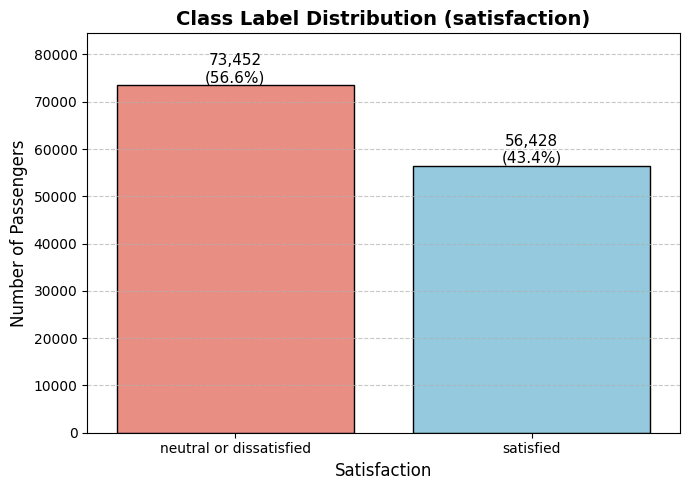

In [49]:
class_counts = df_raw['satisfaction'].value_counts()
class_percent = df_raw['satisfaction'].value_counts(normalize=True) * 100

print("Number of classes:", df_raw['satisfaction'].nunique())
print(pd.DataFrame({'Count': class_counts, 'Percentage (%)': class_percent.round(2)}))

plt.figure(figsize=(7, 5))
ax = sns.countplot(x='satisfaction', data=df_raw, order=class_counts.index,
                   hue='satisfaction', palette=['salmon', 'skyblue'], legend=False, edgecolor='black')

for p, pct in zip(ax.patches, class_percent[class_counts.index]):
    ax.annotate(f'{int(p.get_height()):,}\n({pct:.1f}%)',
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=11)

plt.title('Class Label Distribution (satisfaction)', fontsize=14, fontweight='bold')
plt.xlabel('Satisfaction', fontsize=12)
plt.ylabel('Number of Passengers', fontsize=12)
plt.ylim(0, class_counts.max() * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

The class label `satisfaction` has two classes: **neutral or dissatisfied** with 73,452 passengers (56.6%) and **satisfied** with 56,428 passengers (43.4%).

The dataset is slightly imbalanced toward the "neutral or dissatisfied" class, but the difference (about 57% vs 43%) is not severe, and both classes contain a large number of records. This is consistent with the reference paper, which used a sample of the same dataset with a similar ratio (58.4% vs 41.6%) and considered it balanced. Therefore, we do not need resampling techniques such as oversampling or undersampling. However, when splitting the data into training and testing sets (Section 6.1), we should use a **stratified split** so that every partition keeps the same class ratio.

### 5. Outlier Detection (IQR Method)

The boxplots above show outliers visually. Here we count them using the IQR rule: a value is an outlier if it is below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR.

In [50]:
outlier_rows = []
for col in main_numeric_cols:
    Q1 = df_raw[col].quantile(0.25)
    Q3 = df_raw[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((df_raw[col] < lower) | (df_raw[col] > upper)).sum()
    outlier_rows.append({'Attribute': col, 'Min': df_raw[col].min(), 'Q1': Q1, 'Median': df_raw[col].median(),
                         'Q3': Q3, 'Max': df_raw[col].max(), 'IQR': IQR,
                         'Lower Bound': lower, 'Upper Bound': upper,
                         'Outliers': n_out, 'Outliers (%)': round(n_out / len(df_raw) * 100, 2)})

outlier_table = pd.DataFrame(outlier_rows).set_index('Attribute')
outlier_table

,Min,Q1,Median,Q3,Max,IQR,Lower Bound,Upper Bound,Outliers,Outliers (%)
Attribute,,,,,,,,,,
Age,7.0,27.0,40.0,51.0,85.0,24.0,-9.0,87.0,0,0.00
Flight Distance,31.0,414.0,844.0,1744.0,4983.0,1330.0,-1581.0,3739.0,2855,2.20
Departure Delay in Minutes,0.0,0.0,0.0,12.0,1592.0,12.0,-18.0,30.0,18098,13.93
Arrival Delay in Minutes,0.0,0.0,0.0,13.0,1584.0,13.0,-19.5,32.5,17492,13.47


The table shows the five-number summary (Min, Q1, Median, Q3, Max) together with the IQR bounds and the number of outliers for each numeric attribute:

- **Age:** 0 outliers. All ages (7 to 85) fall inside the IQR bounds, so no treatment is needed.
- **Flight Distance:** 2,855 outliers (2.2%), all above 3,739 miles. These are mostly real long-haul flights, so deleting all of them would lose useful data. However, the wide range (31 to 4,983) means this attribute needs **normalization** so it does not dominate the other attributes.
- **Departure Delay in Minutes:** 18,098 outliers (13.9%), all above 30 minutes.
- **Arrival Delay in Minutes:** 17,492 outliers (13.5%), all above 32.5 minutes.

The delay attributes have a very high share of outliers because most flights have no delay, which makes the IQR very small. Many of these delays are genuine events that may affect satisfaction, so deleting all IQR outliers (about 27% of the data) would lose too much information. Therefore, in preprocessing we used a less strict method (Z-score) that removes only the most extreme values.

### 6. Histograms (Distribution of Numeric Attributes)

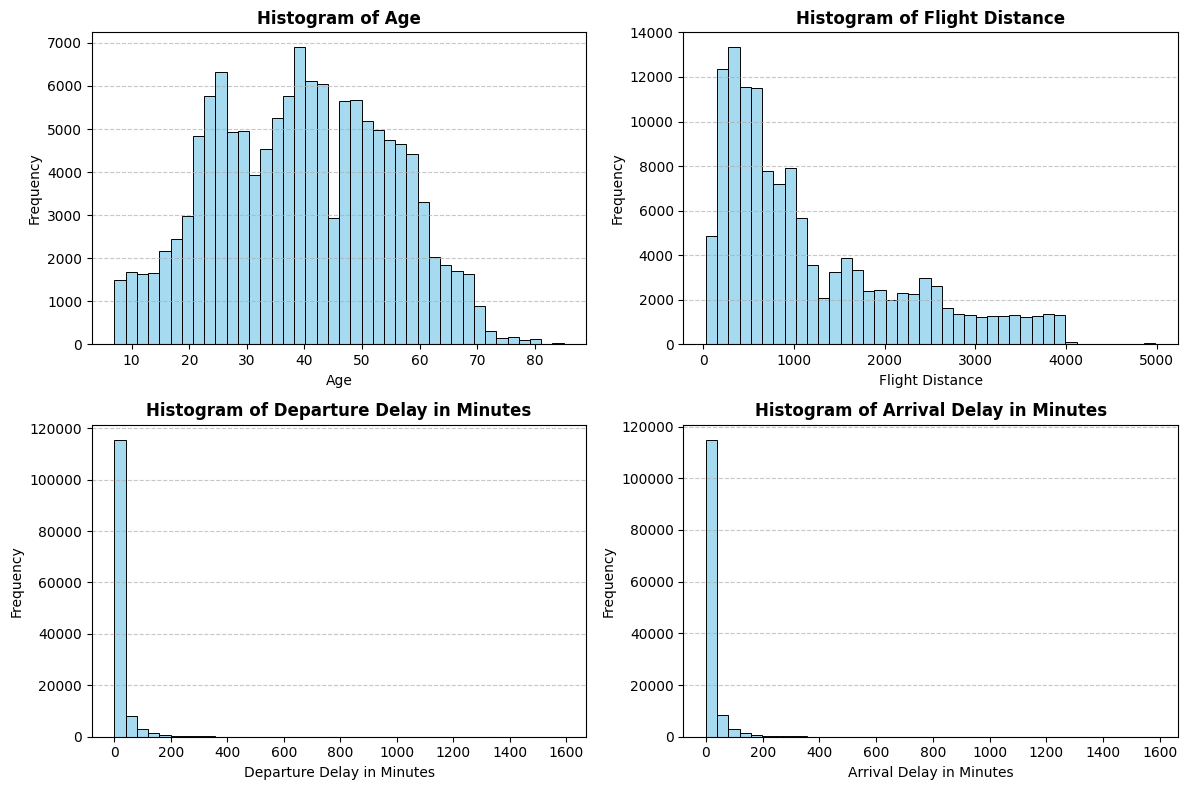

Skewness:
Age                          -0.00
Flight Distance               1.11
Departure Delay in Minutes    6.82
Arrival Delay in Minutes      6.67
dtype: float64


In [51]:
plt.figure(figsize=(12, 8))
for i, col in enumerate(main_numeric_cols, 1):
    plt.subplot(2, 2, i)
    sns.histplot(df_raw[col].dropna(), bins=40, color='skyblue', edgecolor='black')
    plt.title(f'Histogram of {col}', fontsize=12, fontweight='bold')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

print("Skewness:")
print(df_raw[main_numeric_cols].skew().round(2))

The histograms show how the values of each numeric attribute are distributed:

- **Age:** Roughly symmetric (skewness ≈ 0), with about 83% of passengers between 20 and 60 years old. It does not need transformation, but it could be **discretized** into age groups to make it easier to interpret.
- **Flight Distance:** Right-skewed (skewness ≈ 1.1). About 79% of flights are shorter than 2,000 miles, and fewer flights are long-haul.
- **Departure Delay and Arrival Delay:** Extremely right-skewed (skewness ≈ 6.8 and 6.7). About 56% of flights have a delay of 0 minutes, and the frequency drops sharply as the delay increases.

**How this helps preprocessing:** The attributes are on very different scales (Age up to 85, Flight Distance up to about 5,000, delays up to about 1,600), so **normalization** (such as Min-Max scaling) is needed before clustering with K-means, which is based on distance. The strong skew in the delay attributes also shows that extreme values must be handled before normalization.


### 7. Bar Plots (Nominal Attributes vs. Satisfaction)

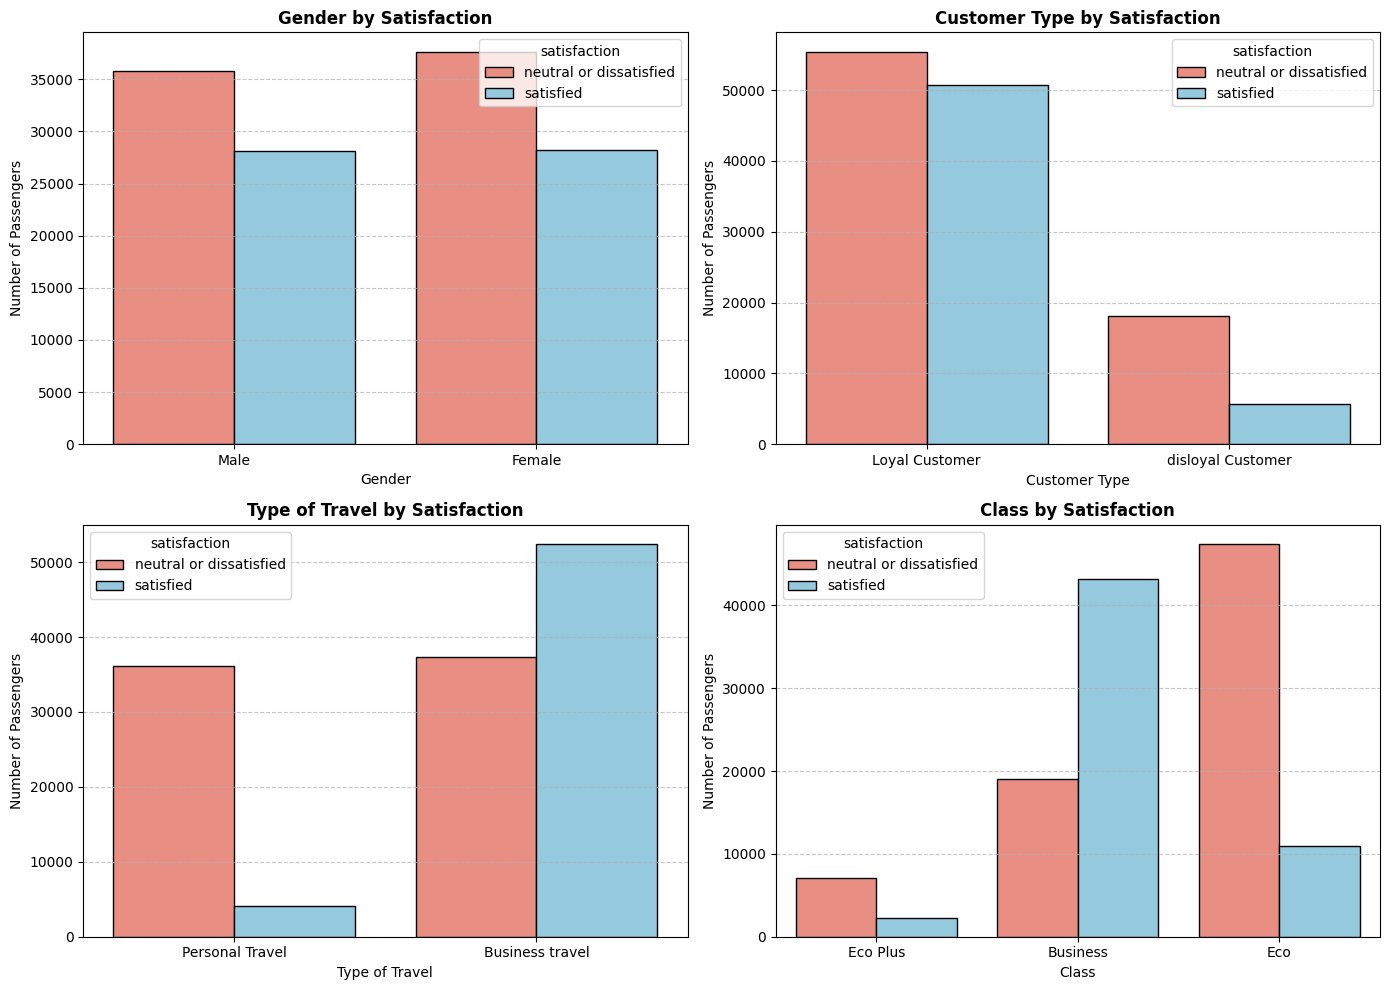


--- Gender: % satisfied in each category ---
Gender
Female    42.9
Male      44.0
Name: satisfied, dtype: float64

--- Customer Type: % satisfied in each category ---
Customer Type
Loyal Customer       47.8
disloyal Customer    24.0
Name: satisfied, dtype: float64

--- Type of Travel: % satisfied in each category ---
Type of Travel
Business travel    58.4
Personal Travel    10.1
Name: satisfied, dtype: float64

--- Class: % satisfied in each category ---
Class
Business    69.4
Eco         18.8
Eco Plus    24.6
Name: satisfied, dtype: float64


In [52]:
nominal_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class']

plt.figure(figsize=(14, 10))
for i, col in enumerate(nominal_cols, 1):
    plt.subplot(2, 2, i)
    ax = sns.countplot(x=col, hue='satisfaction', data=df_raw, palette=['salmon', 'skyblue'], edgecolor='black')
    plt.title(f'{col} by Satisfaction', fontsize=12, fontweight='bold')
    plt.xlabel(col)
    plt.ylabel('Number of Passengers')
    plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

for col in nominal_cols:
    print(f'\n--- {col}: % satisfied in each category ---')
    print((pd.crosstab(df_raw[col], df_raw['satisfaction'], normalize='index')['satisfied'] * 100).round(1))

The bar plots show the count of satisfied and neutral/dissatisfied passengers for each value of the nominal attributes:

- **Gender:** Female and male passengers have almost the same satisfaction rate (42.9% vs 44.0%). Gender has little effect on satisfaction, which is consistent with the reference paper, so it is a candidate to be dropped during **feature selection**.
- **Customer Type:** Loyal customers are satisfied 47.8% of the time, while disloyal customers are satisfied only 24.0% of the time.
- **Type of Travel:** This attribute shows the strongest difference. 58.4% of business travelers are satisfied, compared with only 10.1% of personal travelers.
- **Class:** Business class passengers are the most satisfied (69.4%), while Eco (18.8%) and Eco Plus (24.6%) passengers are mostly neutral or dissatisfied.

**How this helps preprocessing:** These four attributes are stored as text, so they must be converted to numbers (**encoding**, for example label or one-hot encoding) before they can be used by the decision tree and K-means. The plots also show that Customer Type, Type of Travel and Class are strongly related to the class label, so they should be kept, while Gender adds little information.

### 8. Scatter Plot (Departure Delay vs. Arrival Delay)

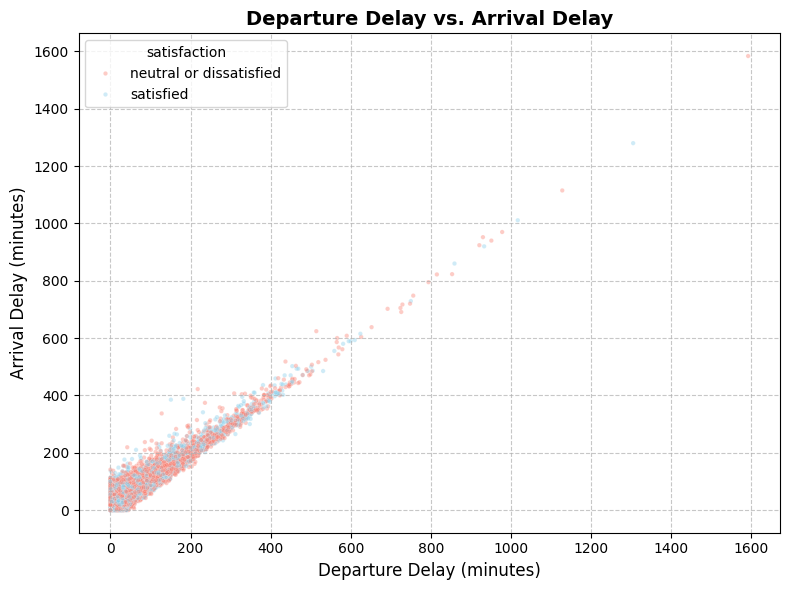

Correlation between Departure Delay and Arrival Delay: 0.965


In [53]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Departure Delay in Minutes', y='Arrival Delay in Minutes', hue='satisfaction',
                data=df_raw, palette=['salmon', 'skyblue'], alpha=0.4, s=10)

plt.title('Departure Delay vs. Arrival Delay', fontsize=14, fontweight='bold')
plt.xlabel('Departure Delay (minutes)', fontsize=12)
plt.ylabel('Arrival Delay (minutes)', fontsize=12)
plt.grid(linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

corr = df_raw['Departure Delay in Minutes'].corr(df_raw['Arrival Delay in Minutes'])
print(f'Correlation between Departure Delay and Arrival Delay: {corr:.3f}')

The scatter plot shows a very strong positive linear relationship between departure delay and arrival delay: the points form an almost straight diagonal line, and the correlation coefficient is **0.965**. This makes sense, because a flight that leaves late usually arrives late by a similar amount of time.

**How this helps preprocessing:**
- Because the two attributes carry almost the same information, they are **redundant**. During **feature selection**, one of them (for example, Arrival Delay, which also has 393 missing values) can be removed.
- The 393 missing values in Arrival Delay are a small share (0.3%), and since the delay data is highly skewed, they can be filled with the median.
- Satisfied and dissatisfied passengers are mixed along the whole line, so delay alone cannot separate the two classes. The service rating attributes will be more important for classification.

# [4] Data Preprocessing

### 1. Raw Dataset

In [54]:

df_raw = pd.read_csv('https://github.com/Layal06-gh/IT326-Airline-Satisfaction/raw/refs/heads/main/Dataset/Raw_dataset.csv')
print(df_raw.head())
print(df_raw.info())
print(df_raw.describe())

   Unnamed: 0      id  Gender      Customer Type  Age   Type of Travel  \
0           0   70172    Male     Loyal Customer   13  Personal Travel   
1           1    5047    Male  disloyal Customer   25  Business travel   
2           2  110028  Female     Loyal Customer   26  Business travel   
3           3   24026  Female     Loyal Customer   25  Business travel   
4           4  119299    Male     Loyal Customer   61  Business travel   

      Class  Flight Distance  Inflight wifi service  \
0  Eco Plus              460                      3   
1  Business              235                      3   
2  Business             1142                      2   
3  Business              562                      2   
4  Business              214                      3   

   Departure/Arrival time convenient  ...  Inflight entertainment  \
0                                  4  ...                       5   
1                                  2  ...                       1   
2                

### 2. Handling Missing Values

In [55]:
from sklearn.impute import SimpleImputer
df_raw_cleaned = df_raw.copy()
df_raw_cleaned = df_raw_cleaned.drop(columns=['Unnamed: 0', 'id'])

print("Missing Values Before", df_raw_cleaned['Arrival Delay in Minutes'].isnull().sum())
print("Rows before", len(df_raw_cleaned))

imputer = SimpleImputer(strategy='median')
df_raw_cleaned['Arrival Delay in Minutes'] = imputer.fit_transform(df_raw_cleaned[['Arrival Delay in Minutes']])
print("Missing Values After" , df_raw_cleaned['Arrival Delay in Minutes'].isnull().sum())
print("Rows after", len(df_raw_cleaned))

Missing Values Before 393
Rows before 129880
Missing Values After 0
Rows after 129880


The missing values plot in the Data Analysis section shows that only
`Arrival Delay in Minutes` has missing values (393 rows, about 0.3% of the data).
Most algorithms cannot
handle NaN values, so they must be treated.
We replaced the missing values (imputation) using `SimpleImputer` from
scikit-learn with the **median** strategy. The median was chosen instead of the
mean because the mean would be pulled up by extreme values (the delay data is highly skewed)
Replacing instead of deleting keeps all rows of the dataset.

### 3. Outlier Removal

In [56]:
from scipy.stats import zscore

outlier_cols = ['Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']

for col in outlier_cols:
    z_scores = zscore(df_raw_cleaned[col])
    threshold = 3

    n_out = (abs(z_scores) > threshold).sum()
    print(f"{col}: {n_out} outliers (|z| > {threshold})")


    df_raw_cleaned = df_raw_cleaned[abs(zscore(df_raw_cleaned[col])) <= threshold]

print("Rows after:", len(df_raw_cleaned))

Flight Distance: 78 outliers (|z| > 3)
Departure Delay in Minutes: 2748 outliers (|z| > 3)
Arrival Delay in Minutes: 3744 outliers (|z| > 3)
Rows after: 123310


#### Outlier Handling (Z-score method)
Flight Distance, Departure Delay, and Arrival Delay contain values far
from the typical range (most delays are near 0, but a few exceed 1,500
minutes). Using the Z-score method we flagged values more than 3 standard deviations from the mean as outliers.

Calculated Z-scores using `scipy.stats.zscore()` for each of the three continuous attributes, and removed rows where |z| > 3.

**Result:** 6570 Rows dropped. This keeps the vast majority of the data while removing extreme values that could distort scaling and clustering.

### 4. Discretization

In [57]:
bins   = [0, 17, 30, 45, 60, 85]
labels = ['Child', 'Young Adult', 'Adult', 'Middle-aged', 'Senior']

df_raw_cleaned['Age Group'] = pd.cut(df_raw_cleaned['Age'], bins=bins, labels=labels)

print("Age groups:")
display(df_raw_cleaned[['Age', 'Age Group']].head())
print(df_raw_cleaned['Age Group'].value_counts().sort_index())

df_raw_cleaned['Age Group'] = df_raw_cleaned['Age Group'].cat.codes
df_raw_cleaned = df_raw_cleaned.drop(columns=['Age'])

Age groups:


,Age,Age Group
0,13,Child
1,25,Young Adult
2,26,Young Adult
3,25,Young Adult
4,61,Senior


Age Group
Child           9327
Young Adult    29450
Adult          39333
Middle-aged    35650
Senior          9550
Name: count, dtype: int64


We grouped Age into five ordered categories (Child, Young Adult, Adult, Middle-aged, Senior), encoded them as 0–4, and dropped the original column. Age has no outliers, but grouping it makes the decision tree rules easier to interpret. Result: Adult is the largest group (39,333) and Child the smallest (9,327).

### 5. Encoding

In [58]:
nominal_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction']

print("Before Encoding:")
display(df_raw_cleaned[nominal_cols].head())

df_raw_cleaned['Gender']         = df_raw_cleaned['Gender'].map({'Female': 0, 'Male': 1})
df_raw_cleaned['Customer Type']  = df_raw_cleaned['Customer Type'].map({'disloyal Customer': 0, 'Loyal Customer': 1})
df_raw_cleaned['Type of Travel'] = df_raw_cleaned['Type of Travel'].map({'Personal Travel': 0, 'Business travel': 1})
df_raw_cleaned['Class']          = df_raw_cleaned['Class'].map({'Eco': 0, 'Eco Plus': 1, 'Business': 2})
df_raw_cleaned['satisfaction']   = df_raw_cleaned['satisfaction'].map({'neutral or dissatisfied': 0, 'satisfied': 1})

print("After Encoding:")
display(df_raw_cleaned[nominal_cols].head())

Before Encoding:


,Gender,Customer Type,Type of Travel,Class,satisfaction
0,Male,Loyal Customer,Personal Travel,Eco Plus,neutral or dissatisfied
1,Male,disloyal Customer,Business travel,Business,neutral or dissatisfied
2,Female,Loyal Customer,Business travel,Business,satisfied
3,Female,Loyal Customer,Business travel,Business,neutral or dissatisfied
4,Male,Loyal Customer,Business travel,Business,satisfied


After Encoding:


,Gender,Customer Type,Type of Travel,Class,satisfaction
0,1,1,0,1,0
1,1,0,1,2,0
2,0,1,1,2,1
3,0,1,1,2,0
4,1,1,1,2,1


We converted the five text attributes to numbers: Gender, Customer Type, Type of Travel and satisfaction to 0/1, and Class to 0/1/2 (Eco, Eco Plus, Business) to keep its order. The decision tree and K-means cannot work with text. Result: All attributes are now numeric.

### 6. Normalization

In [59]:
from sklearn.preprocessing import MinMaxScaler

feature_cols = df_raw_cleaned.columns.drop('satisfaction')

print("Before Normalization:")
display(df_raw_cleaned[feature_cols].head())

scaler = MinMaxScaler()
df_raw_cleaned[feature_cols] = scaler.fit_transform(df_raw_cleaned[feature_cols])

print("After Normalization:")
display(df_raw_cleaned[feature_cols].head())

Before Normalization:


,Gender,Customer Type,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Age Group
0,1,1,0,1,460,3,4,3,1,5,...,5,4,3,4,4,5,5,25,18.0,0
1,1,0,1,2,235,3,2,3,3,1,...,1,1,5,3,1,4,1,1,6.0,1
2,0,1,1,2,1142,2,2,2,2,5,...,5,4,3,4,4,4,5,0,0.0,1
3,0,1,1,2,562,2,5,5,5,2,...,2,2,5,3,1,4,2,11,9.0,1
4,1,1,1,2,214,3,3,3,3,4,...,3,3,4,4,3,3,3,0,0.0,4


After Normalization:


,Gender,Customer Type,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Age Group
0,1.0,1.0,0.0,0.5,0.108088,0.6,0.8,0.6,0.2,1.0,...,1.0,0.8,0.6,0.75,0.75,1.0,1.0,0.196850,0.230769,0.00
1,1.0,0.0,1.0,1.0,0.051398,0.6,0.4,0.6,0.6,0.2,...,0.2,0.2,1.0,0.50,0.00,0.8,0.2,0.007874,0.076923,0.25
2,0.0,1.0,1.0,1.0,0.279919,0.4,0.4,0.4,0.4,1.0,...,1.0,0.8,0.6,0.75,0.75,0.8,1.0,0.000000,0.000000,0.25
3,0.0,1.0,1.0,1.0,0.133787,0.4,1.0,1.0,1.0,0.4,...,0.4,0.4,1.0,0.50,0.00,0.8,0.4,0.086614,0.115385,0.25
4,1.0,1.0,1.0,1.0,0.046107,0.6,0.6,0.6,0.6,0.8,...,0.6,0.6,0.8,0.75,0.50,0.6,0.6,0.000000,0.000000,1.00


We applied Min-Max normalization to all 22 attributes except satisfaction, scaling them to 0–1. The attributes had very different ranges (Flight Distance up to ~4,000, ratings 0–5), so larger attributes would dominate the distance in K-means. It was applied after outlier removal, since outliers would squeeze most values near 0. Result: All attributes contribute equally.

### 7. Preprocessed Dataset:

In [60]:
print("Final shape:", df_raw_cleaned.shape)
display(df_raw_cleaned.head())

df_raw_cleaned.to_csv('Preprocessed_dataset.csv', index=False)

Final shape: (123310, 23)


,Gender,Customer Type,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,...,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction,Age Group
0,1.0,1.0,0.0,0.5,0.108088,0.6,0.8,0.6,0.2,1.0,...,0.8,0.6,0.75,0.75,1.0,1.0,0.196850,0.230769,0,0.00
1,1.0,0.0,1.0,1.0,0.051398,0.6,0.4,0.6,0.6,0.2,...,0.2,1.0,0.50,0.00,0.8,0.2,0.007874,0.076923,0,0.25
2,0.0,1.0,1.0,1.0,0.279919,0.4,0.4,0.4,0.4,1.0,...,0.8,0.6,0.75,0.75,0.8,1.0,0.000000,0.000000,1,0.25
3,0.0,1.0,1.0,1.0,0.133787,0.4,1.0,1.0,1.0,0.4,...,0.4,1.0,0.50,0.00,0.8,0.4,0.086614,0.115385,0,0.25
4,1.0,1.0,1.0,1.0,0.046107,0.6,0.6,0.6,0.6,0.8,...,0.6,0.8,0.75,0.50,0.6,0.6,0.000000,0.000000,1,1.00


The final dataset has 123,310 rows and 23 attributes, with no missing values and all values numeric, ready for the data mining techniques in the following sections. It was saved as Preprocessed_dataset.csv.

### 8. Feature Selection

No attributes were removed by feature selection. Although Gender and Arrival Delay showed little additional information in the data analysis, decision trees select the most informative attributes automatically during splitting, so all 22 attributes were kept.

### Loading the Preprocessed Dataset

The preprocessed dataset produced above is loaded from the project repository and used in all the following sections.

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

raw_url = 'https://github.com/Layal06-gh/IT326-Airline-Satisfaction/raw/refs/heads/main/Dataset/Raw_dataset.csv'
url = 'https://github.com/Layal06-gh/IT326-Airline-Satisfaction/raw/refs/heads/main/Dataset/Preprocessed_dataset.csv'

df_raw = pd.read_csv(raw_url)
df = pd.read_csv(url)

print("Raw shape:", df_raw.shape)
print("Preprocessed shape:", df.shape)
print(df['satisfaction'].value_counts())

Raw shape: (129880, 25)
Preprocessed shape: (123310, 23)
satisfaction
0    69241
1    54069
Name: count, dtype: int64


# [5] Data Mining Technique

## 5.1 Classification: Decision Tree

**What:** A Decision Tree is a supervised classification technique. It is built in a
greedy, top-down, recursive divide-and-conquer manner: all training tuples start at the
root, then the data is partitioned recursively based on the attribute that best separates
the classes. Partitioning stops when all tuples in a node belong to the same class, when
no attributes remain (majority voting is used), or when no tuples are left. Internal nodes
represent attribute tests, and leaf nodes represent the class label.

To choose the splitting attribute, we use two attribute selection measures:
- **Gini index (CART):** measures the impurity of a node. The attribute with the smallest
  weighted Gini (largest reduction in impurity) is selected. It always produces binary splits.
- **Information Gain (entropy):** the attribute with the highest information gain is selected.

**Why:** Our problem is a classification task with a labeled class attribute
(`satisfaction`: satisfied / neutral or dissatisfied). Decision trees are easy to
interpret, because they produce clear rules that show which service factors drive
passenger satisfaction. This directly serves our goal of helping airlines prioritize
improvements.

**How (Python packages and methods):**

| Package | Method | Purpose |
|---|---|---|
| `sklearn.model_selection` | `train_test_split(test_size, random_state=42, stratify=y)` | Holdout partitioning into 90/10, 80/20 and 70/30, keeping the class ratio |
| `sklearn.tree` | `DecisionTreeClassifier(criterion="gini")` | Build the tree using the Gini index |
| `sklearn.tree` | `DecisionTreeClassifier(criterion="entropy")` | Build the tree using Information Gain |
| `sklearn.tree` | `plot_tree()` | Visualize the final tree |
| `sklearn.metrics` | `accuracy_score()` | Compute accuracy = (TP + TN) / total |
| `sklearn.metrics` | `confusion_matrix(labels=[1, 0])`, `ConfusionMatrixDisplay` | Build and plot the confusion matrix (positive class: satisfied) |

Since all attributes are numeric after preprocessing, the tree splits continuous attributes
using binary splits on a threshold (A ≤ split point, A > split point).

## 5.2 Clustering: K-means

K-means is a centroid-based, partitioning clustering algorithm that groups unlabeled data into $K$ distinct clusters by minimizing the total within-cluster sum of squares (WSS / Inertia). Each data point is iteratively assigned to the nearest cluster centroid based on Euclidean distance, and the centroids are recalculated until convergence.

**Why:**
Our goal is to discover natural segments and underlying behavioral patterns among airline passengers without relying on the target label (`satisfaction`). Clustering helps identify distinct passenger profiles (e.g., highly satisfied business travelers vs. dissatisfied economy travelers), allowing airlines to understand specific passenger needs and tailor services accordingly.

**How (Python packages and methods):**

| Package | Method | Purpose |
| :--- | :--- | :--- |
| `sklearn.cluster` | `KMeans(n_clusters=k, random_state=42, n_init=10)` | Apply K-means clustering algorithm and compute cluster centroids. |
| `sklearn.metrics` | `silhouette_score(X, labels, sample_size=10000, random_state=42)` | Evaluate clustering quality and separation (using a sample of 10,000 instances to handle the large dataset efficiently). |
| `matplotlib.pyplot` | `plot()` | Visualize the Elbow method curve to justify the optimal value of $K$. |

*Note: All features are numeric and normalized after preprocessing, and the target column (`satisfaction`) is removed prior to clustering.*

# [6] Evaluation and Comparison

## 6.1 Classification

### 6.1.1 Gini Index (90/10, 80/20, 70/30)



In [62]:
X = df.drop(columns=['satisfaction'])
y = df['satisfaction']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (123310, 22)
y shape: (123310,)


In [63]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42, stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print()
print("Class ratio in training:")
print(y_train.value_counts(normalize=True).round(3))
print()
print("Class ratio in testing:")
print(y_test.value_counts(normalize=True).round(3))

Training rows: 110979
Testing rows: 12331

Class ratio in training:
satisfaction
0    0.562
1    0.438
Name: proportion, dtype: float64

Class ratio in testing:
satisfaction
0    0.562
1    0.438
Name: proportion, dtype: float64


In [64]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

gini_tree = DecisionTreeClassifier(criterion='gini', random_state=42)
gini_tree.fit(X_train, y_train)

train_acc = accuracy_score(y_train, gini_tree.predict(X_train))
test_acc  = accuracy_score(y_test,  gini_tree.predict(X_test))

print("Training accuracy:", round(train_acc * 100, 2), "%")
print("Testing accuracy: ", round(test_acc * 100, 2), "%")
print("Tree depth:", gini_tree.get_depth())
print("Number of leaves:", gini_tree.get_n_leaves())

Training accuracy: 100.0 %
Testing accuracy:  94.45 %
Tree depth: 40
Number of leaves: 4369


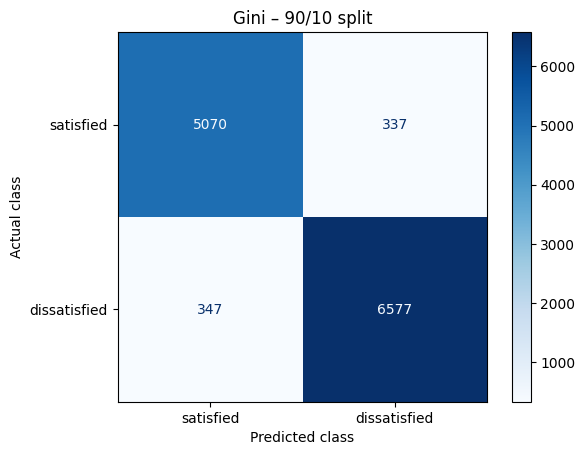

In [65]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = gini_tree.predict(X_test)
cm = confusion_matrix(y_test, y_pred, labels=[1, 0])

disp = ConfusionMatrixDisplay(cm, display_labels=['satisfied', 'dissatisfied'])
disp.plot(cmap='Blues', values_format='d')
plt.title('Gini – 90/10 split')
plt.xlabel('Predicted class')
plt.ylabel('Actual class')
plt.show()

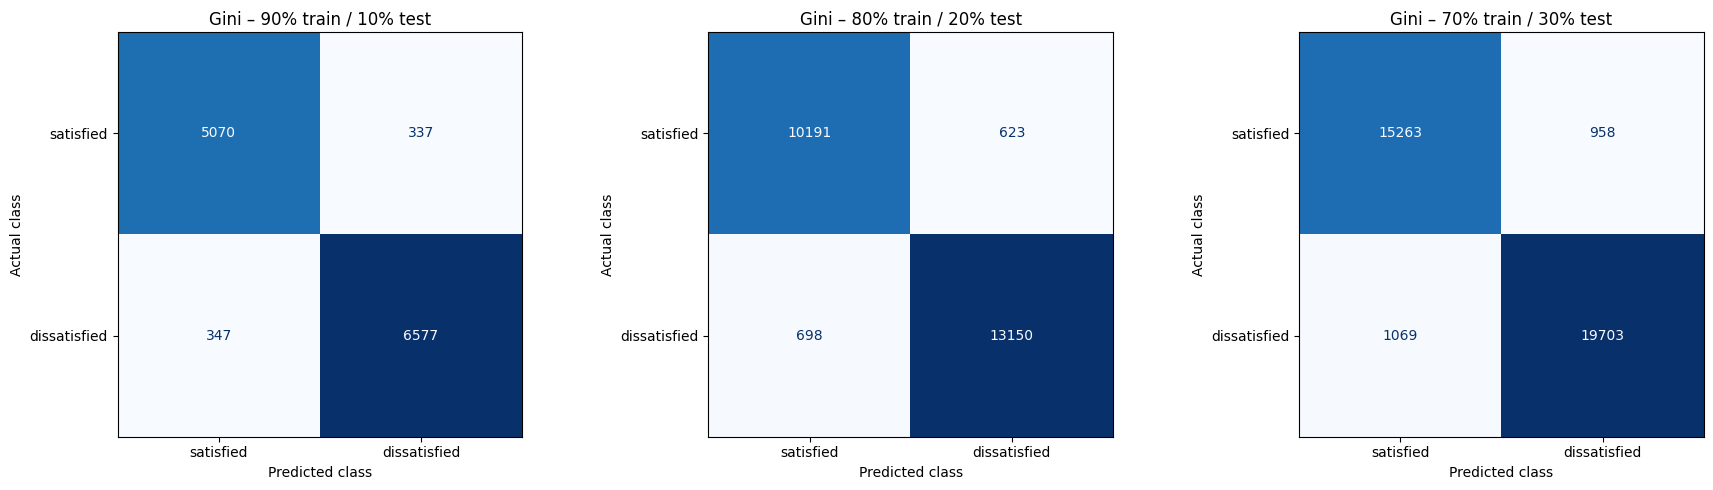

,Partition,Training accuracy (%),Testing accuracy (%)
0,90% train / 10% test,100.0,94.45
1,80% train / 20% test,100.0,94.64
2,70% train / 30% test,100.0,94.52


In [66]:
splits = [0.1, 0.2, 0.3]
results = []

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, test_size in enumerate(splits):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )

    tree = DecisionTreeClassifier(criterion='gini', random_state=42)
    tree.fit(X_tr, y_tr)

    y_pred = tree.predict(X_te)
    train_acc = accuracy_score(y_tr, tree.predict(X_tr))
    test_acc = accuracy_score(y_te, y_pred)

    label = f"{int((1 - test_size) * 100)}% train / {int(test_size * 100)}% test"
    results.append([label, round(train_acc * 100, 2), round(test_acc * 100, 2)])

    cm = confusion_matrix(y_te, y_pred, labels=[1, 0])
    ConfusionMatrixDisplay(cm, display_labels=['satisfied', 'dissatisfied']).plot(
        ax=axes[i], cmap='Blues', values_format='d', colorbar=False
    )
    axes[i].set_title(f"Gini – {label}")
    axes[i].set_xlabel('Predicted class')
    axes[i].set_ylabel('Actual class')

plt.tight_layout()
plt.show()

gini_results = pd.DataFrame(results, columns=['Partition', 'Training accuracy (%)', 'Testing accuracy (%)'])
gini_results

**Gini Index – Results Interpretation**

The 80% train / 20% test partition achieved the highest testing accuracy (94.64%),
followed by 70/30 (94.52%) and 90/10 (94.45%). The difference between the best and
worst partition is only 0.19 percentage points, which means the partition size has
very little effect on performance. This is because the dataset is large: even the
smallest training set (70%) contains more than 86,000 passengers, which is enough
for the tree to learn the patterns.

In all confusion matrices, most passengers are on the diagonal (TP and TN), and the
numbers of FP and FN are close to each other, so the model does not favor one class.

The training accuracy is 100% in all partitions, while the testing error is low
(about 5.5%). According to the training vs testing error criteria, this is close to
a good fit. However, the 0% training error and the very deep tree (about 40 levels,
thousands of leaves) show signs of overfitting: the tree memorized the training data.

### 6.1.2 Information Gain – Entropy (90/10, 80/20, 70/30)



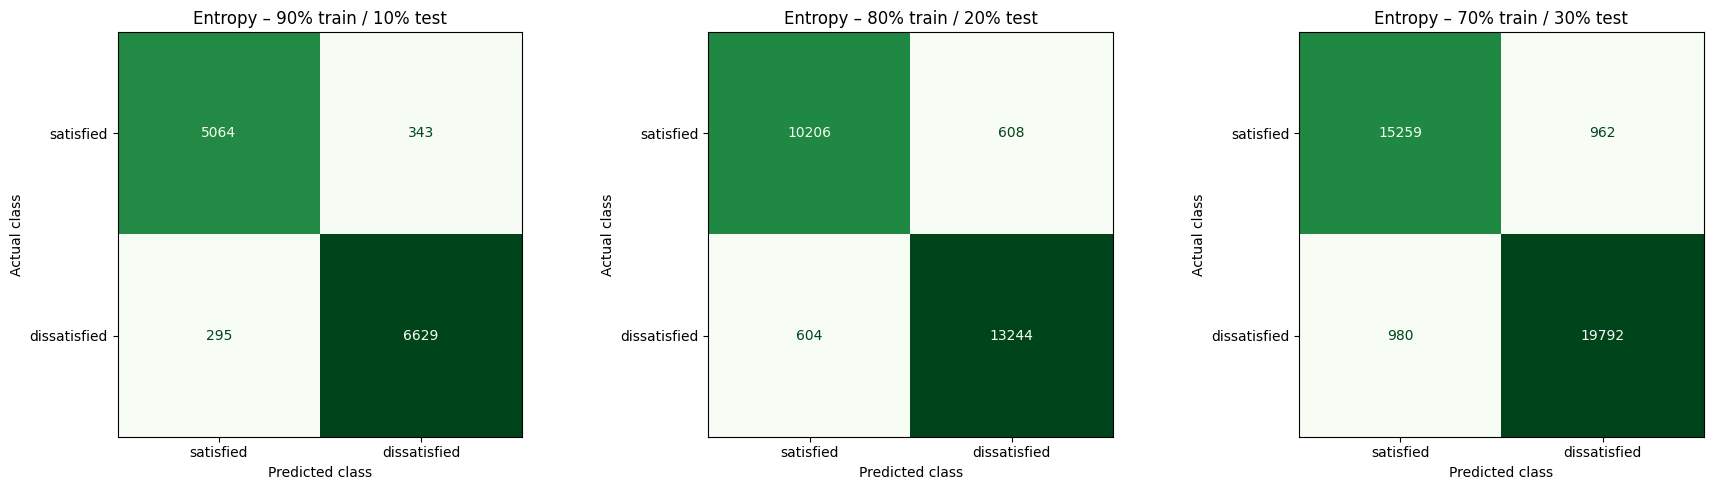


--- Entropy Index Results ---


,Partition,Training accuracy (%),Testing accuracy (%)
0,90% train / 10% test,100.0,94.83
1,80% train / 20% test,100.0,95.09
2,70% train / 30% test,100.0,94.75


In [67]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import pandas as pd
import matplotlib.pyplot as plt

splits = [0.1, 0.2, 0.3]
entropy_results = []

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, test_size in enumerate(splits):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )

    tree_ent = DecisionTreeClassifier(criterion='entropy', random_state=42)
    tree_ent.fit(X_tr, y_tr)

    y_pred = tree_ent.predict(X_te)
    train_acc = accuracy_score(y_tr, tree_ent.predict(X_tr))
    test_acc = accuracy_score(y_te, y_pred)

    label = f"{int((1-test_size)*100)}% train / {int(test_size * 100)}% test"
    entropy_results.append([label, round(train_acc * 100, 2), round(test_acc * 100, 2)])

    cm = confusion_matrix(y_te, y_pred, labels=[1, 0])
    ConfusionMatrixDisplay(cm, display_labels=['satisfied', 'dissatisfied']).plot(
        ax=axes[i], cmap='Greens', values_format='d', colorbar=False
    )
    axes[i].set_title(f"Entropy – {label}")
    axes[i].set_xlabel('Predicted class')
    axes[i].set_ylabel('Actual class')

plt.tight_layout()
plt.show()

df_entropy_results = pd.DataFrame(entropy_results, columns=['Partition', 'Training accuracy (%)', 'Testing accuracy (%)'])
print("\n--- Entropy Index Results ---")
display(df_entropy_results)

**Pruned Decision Tree (Entropy, max_depth = 3) for Interpretability**

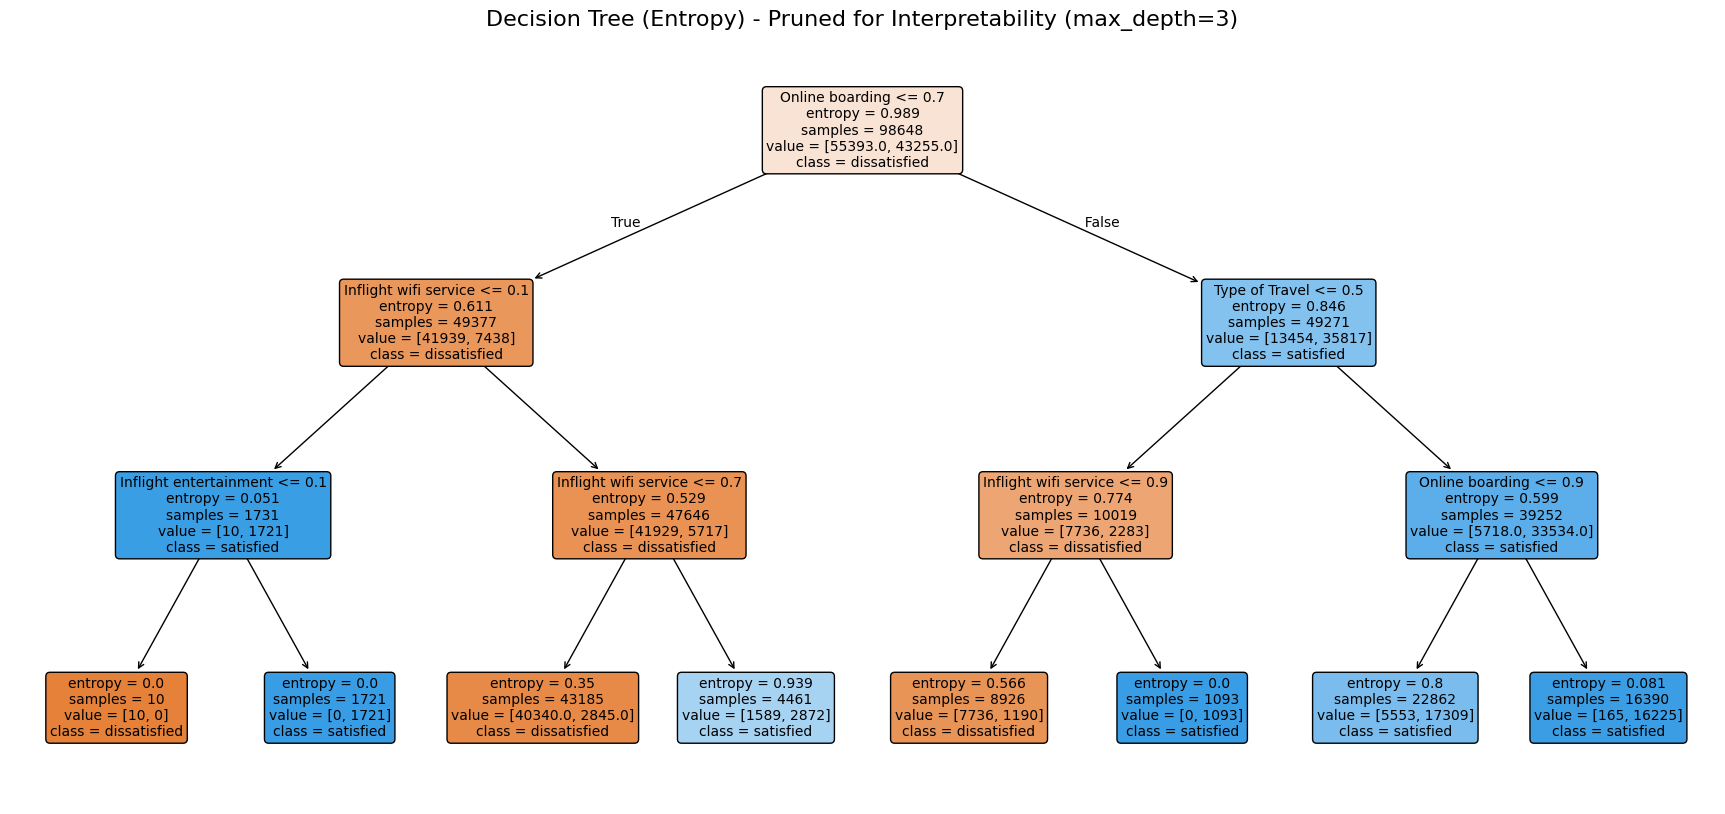


--- Top Features Influencing Passenger Satisfaction ---
Online boarding           0.552401
Inflight wifi service     0.251654
Type of Travel            0.194289
Inflight entertainment    0.001656
dtype: float64


In [68]:
from sklearn.tree import plot_tree

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

pruned_tree = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
pruned_tree.fit(X_tr, y_tr)

plt.figure(figsize=(22, 10))
plot_tree(pruned_tree,
          feature_names=X.columns,
          class_names=['dissatisfied', 'satisfied'],
          filled=True,
          rounded=True,
          fontsize=10)
plt.title("Decision Tree (Entropy) - Pruned for Interpretability (max_depth=3)", fontsize=16)
plt.show()

importances = pd.Series(pruned_tree.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\n--- Top Features Influencing Passenger Satisfaction ---")
print(importances[importances > 0])

### 6.1.3 Comparison: Gini vs Entropy



When comparing the performance of the Decision Tree algorithms across the three data partitions, the Information Gain (Entropy) criterion consistently outperformed the Gini index. For the 90/10 partition, Entropy achieved a testing accuracy of 94.83% compared to Gini's 94.45%. For the 80/20 partition, Entropy reached 95.09% against Gini's 94.64%. Finally, in the 70/30 partition, Entropy scored 94.75% while Gini scored 94.52%. According to these evaluation metrics, the Information Gain (Entropy) model is the best-performing algorithm for each individual partition. Consequently, the best overall model across all configurations is the Entropy-based Decision Tree using the 80% training and 20% testing split, which yielded the highest overall testing accuracy of 95.09% while maintaining a balanced distribution of false positive and false negative predictions.

## 6.2 Clustering

### 6.2.1 Elbow Method and Choice of K

To determine the suitable range of clusters, the Elbow Method was applied by computing the Total Within-Cluster Sum of Squares (WSS / Inertia) for values of $K$ ranging from 2 to 8.

As shown in the plot below, a noticeable bend and reduction in the rate of WSS decrease begins to appear between $K = 3$ and $K = 5$. Based on this observation, three candidate values were selected for detailed evaluation: **$K = 3$**, **$K = 4$**, and **$K = 5$**.

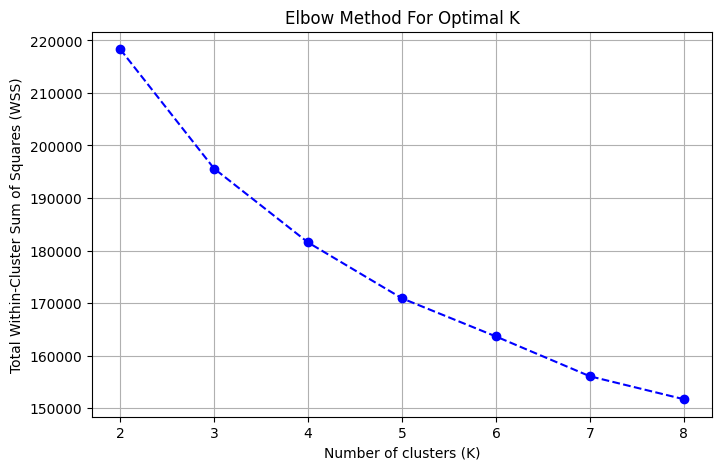

In [69]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

X_cluster = df.drop(columns=['satisfaction'], errors='ignore')

wcss = []
k_range = range(2, 9)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_cluster)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss, marker='o', linestyle='--', color='b')
plt.title('Elbow Method For Optimal K')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Total Within-Cluster Sum of Squares (WSS)')
plt.grid(True)
plt.show()

### 6.2.2 Silhouette and Total Within-Cluster Sum of Squares



In [70]:
chosen_k = [3, 4, 5]
results = []

for k in chosen_k:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_cluster)

    # Total Within-Cluster Sum of Squares (Inertia)
    wcss_val = kmeans.inertia_

    # Average Silhouette Width on a 10,000-row sample (for speed)
    sil_val = silhouette_score(X_cluster, labels, sample_size=10000, random_state=42)

    results.append({
        'K': k,
        'WSS (Inertia)': round(wcss_val, 2),
        'Average Silhouette Width': round(sil_val, 4)
    })

# Comparison table
results_df = pd.DataFrame(results)
print(results_df)

   K  WSS (Inertia)  Average Silhouette Width
0  3      195596.28                    0.1687
1  4      181535.42                    0.1466
2  5      170903.20                    0.1431


To evaluate the clustering quality and identify the optimal number of clusters, the Total Within-Cluster Sum of Squares (WSS) and the Average Silhouette Width were calculated across the three candidate values: $K \in \{3, 4, 5\}$.

> **Computational Note:** Due to the large scale of the dataset (123,310 records) and the quadratic complexity of distance calculations, the Average Silhouette Width was computed using a representative random sample of 10,000 observations (`sample_size=10000`, `random_state=42`) to prevent memory exhaustion while maintaining statistical validity.

### Clustering Evaluation Results:

| Metric | $K = 3$ | $K = 4$ | $K = 5$ |
| :--- | :---: | :---: | :---: |
| **Total Within-Cluster Sum of Squares (WSS)** | 195,596.28 | 181,535.42 | 170,903.20 |
| **Average Silhouette Width** | **0.1687** | 0.1466 | 0.1431 |

---

### Optimal Number of Clusters (Best K):
Based on the **Majority Rule**, **$K = 3$** is identified as the optimal number of clusters:
1. **Average Silhouette Width:** $K = 3$ achieved the highest score (**0.1687**), indicating that clusters formed at this level have better cohesion and separation compared to $K = 4$ (0.1466) and $K = 5$ (0.1431).
2. **Elbow Method Consistency:** $K = 3$ aligns with the primary inflection point observed in the Elbow plot, where the steepest reduction in within-cluster variation occurs before transitioning into a more gradual decline.

### 6.2.3 Cluster Visualization




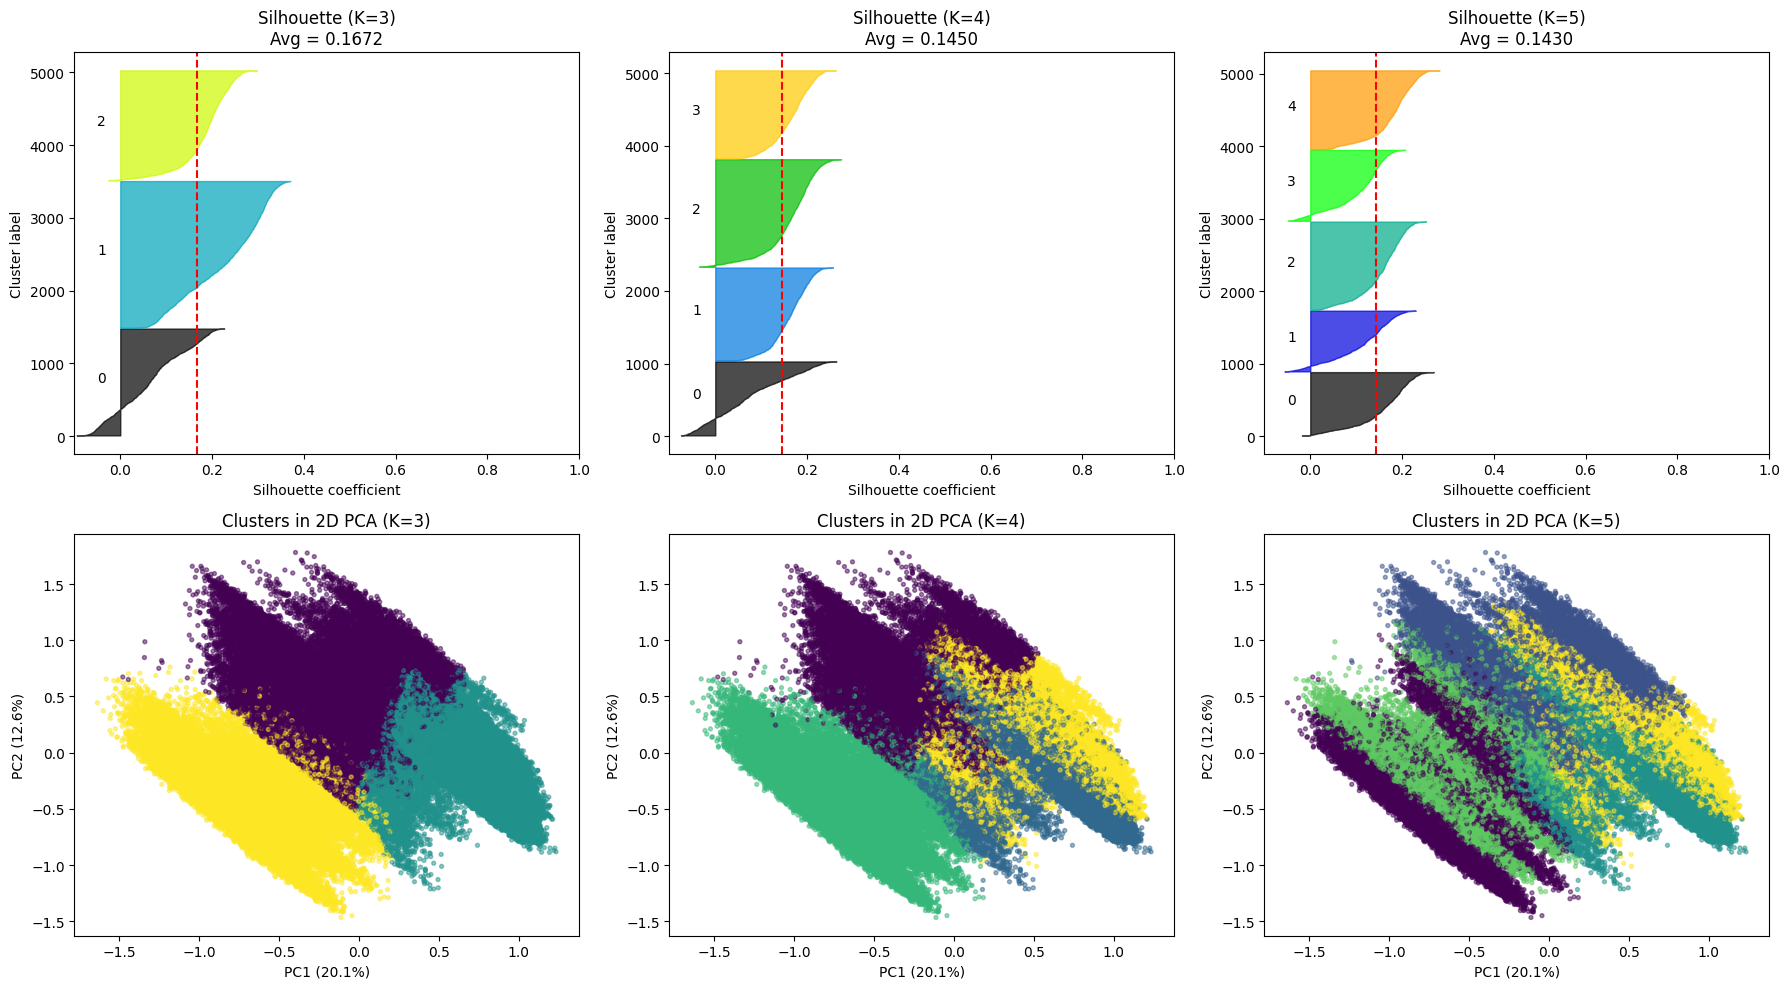

In [71]:
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_cluster)


np.random.seed(42)
sample_idx = np.random.choice(len(X_cluster), size=5000, replace=False)
X_sil_sample = X_cluster.iloc[sample_idx]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for i, k in enumerate([3, 4, 5]):

    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_full = kmeans.fit_predict(X_cluster)
    labels_sample = labels_full[sample_idx]

    #  Silhouette plot
    ax_sil = axes[0, i]
    sil_vals = silhouette_samples(X_sil_sample, labels_sample)
    y_lower = 10

    for c in range(k):
        ith_sil = np.sort(sil_vals[labels_sample == c])
        size_c = ith_sil.shape[0]
        y_upper = y_lower + size_c
        color = cm.nipy_spectral(c / k)
        ax_sil.fill_betweenx(np.arange(y_lower, y_upper),
                             0, ith_sil,
                             facecolor=color, edgecolor=color, alpha=0.7)
        ax_sil.text(-0.05, y_lower + size_c / 2, str(c))
        y_lower = y_upper + 10

    avg_sil = silhouette_score(X_sil_sample, labels_sample)
    ax_sil.axvline(x=avg_sil, color="red", linestyle="--")
    ax_sil.set_title(f"Silhouette (K={k})\nAvg = {avg_sil:.4f}")
    ax_sil.set_xlabel("Silhouette coefficient")
    ax_sil.set_ylabel("Cluster label")
    ax_sil.set_xlim([-0.1, 1.0])

    # 2D scatter (PCA)
    ax_sc = axes[1, i]
    sc = ax_sc.scatter(X_pca[:, 0], X_pca[:, 1],
                       c=labels_full, cmap='viridis', s=8, alpha=0.5)
    ax_sc.set_title(f"Clusters in 2D PCA (K={k})")
    ax_sc.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
    ax_sc.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")

plt.tight_layout()
plt.show()

 The silhouette plots show that K = 3 has the highest average silhouette width, indicating the best-separated clusters, which agrees with the results in Section 6.2.2. The PCA scatter shows that the clusters partially overlap. This is expected, because passengers' service ratings change gradually rather than forming sharply separated groups, which also explains the relatively low silhouette values (below 0.2).

Each knife shape is a cluster; the red dashed line is the average silhouette width. Uniform, well-above-average knives mean well-separated clusters; thin or below-zero knives mean that cluster overlaps with its neighbors.

# [7] Findings and Discussion

The evaluation of the classification models reveals that the Entropy-based Decision Tree (80/20 split) is the most effective at predicting airline passenger satisfaction, achieving a 95.09% accuracy rate. To mitigate the overfitting observed in the fully grown models and to extract meaningful business insights, a pruned decision tree with a maximum depth of 3 was generated to provide a highly interpretable visual representation of the decision rules. The feature importance analysis extracted from this pruned tree indicates that digital convenience is the primary driver of customer satisfaction. "Online boarding" is by far the most influential factor (accounting for 55.2% of the predictive weight), followed closely by "Inflight wifi service" (25.1%) and "Type of Travel" (19.4%). The root node of the tree clearly demonstrates that passengers reporting high satisfaction with online boarding are significantly more likely to be classified as satisfied overall. These findings are highly actionable in an industry context, suggesting that if airlines want to maximize overall passenger satisfaction, prioritizing investments in seamless digital check-in workflows and reliable in-flight connectivity will yield the highest return on investment.   

## 7.1 Classification Findings

**Gini Index Findings**

The Gini decision tree predicts passenger satisfaction with about 94.6% accuracy
(best on the 80/20 partition), which shows that the service ratings and travel
characteristics carry strong information about passenger satisfaction. Since the
errors are balanced between FP and FN, and the classes are only slightly imbalanced
(56% / 44%), accuracy is a reliable measure here.

From the problem's perspective, this result is meaningful: an airline could use this
model to identify passengers who are likely to be dissatisfied and focus on the service
factors that matter most to them. As discussed in Section 6.1.1, the full tree shows
signs of overfitting, so the final tree is visualized with a limited depth to keep its
rules interpretable.

The Entropy (Information Gain) decision tree model successfully predicted passenger satisfaction with a highest testing accuracy of 95.09% achieved on the 80% training / 20% test partition (outperforming the 90/10 partition at 94.83% and the 70/30 partition at 94.75%). This confirms that Information Gain is highly effective at splitting nodes for this dataset.

Furthermore, investigating the feature importance and the pruned tree structure (max_depth=3) revealed that Online boarding is the most dominant factor influencing passenger satisfaction (accounting for over 55% of feature importance), followed by Inflight wifi service and Type of Travel. This indicates that digital touchpoints and in-flight connectivity are critical determinants of whether a passenger leaves neutral/dissatisfied or satisfied.

## 7.2 Clustering Findings

**The K = 3** clusters were profiled by computing the mean of each normalized attribute per cluster (see the profile table below). The clusters are separated mainly by Type of Travel, Class, Customer Type and the service ratings, while delays and gender are nearly identical across clusters. Although satisfaction was removed before clustering, the clusters differ strongly on it, which shows that the segments capture real differences in passenger experience.

**Cluster 1 –** Satisfied loyal business travelers (85% satisfied). Almost all are loyal business-class passengers on the longest flights. They give the highest ratings to nearly every service, especially inflight entertainment (0.83), online boarding (0.82) and seat comfort (0.79).

**Cluster 0 –** Dissatisfied business travelers in lower classes (24% satisfied). They travel for business, but mostly in Economy or Eco Plus, and only about half are loyal customers. They give the lowest ratings for seat comfort (0.45) and check-in service (0.46), and low ratings for wifi (0.50) and online boarding (0.53).

**Cluster 2 –** Dissatisfied loyal leisure travelers (10% satisfied). All are personal-travel passengers, almost entirely in Economy, on short flights. Their ratings are mid-range, but the digital services are weak: ease of online booking (0.49), wifi (0.50) and online boarding (0.56). Only departure/arrival time convenience (0.73) scores well.

These profiles agree with the classification results. The services that separate the satisfied cluster from the others (online boarding, wifi, type of travel) are the same ones the decision tree ranked as most important. For airlines, this suggests two different priorities: improving the economy cabin experience (seat comfort, check-in) for business passengers in Cluster 0, and improving digital services (online booking, boarding, wifi) for leisure passengers in Cluster 2. Even loyal customers in Cluster 2 are unhappy, so loyalty alone does not protect against dissatisfaction.

**Limitations.** The silhouette widths are low (0.14–0.17), so the clusters overlap. Because the binary attributes (Type of Travel, Customer Type, Class) take the full 0–1 range, they have a large influence on the Euclidean distance and drive much of the segmentation. The clusters should therefore be read as broad passenger profiles.


cluster,0,1,2
Gender,0.46,0.51,0.50
Customer Type,0.47,0.94,1.00
Type of Travel,1.00,0.99,0.00
Class,0.37,0.94,0.11
Flight Distance,0.21,0.43,0.19
Inflight wifi service,0.50,0.62,0.50
Departure/Arrival time convenient,0.51,0.60,0.73
Ease of Online booking,0.54,0.61,0.49
Gate location,0.59,0.61,0.58
Food and drink,0.56,0.73,0.62


cluster
0    0.235
1    0.851
2    0.103
Name: satisfaction, dtype: float64


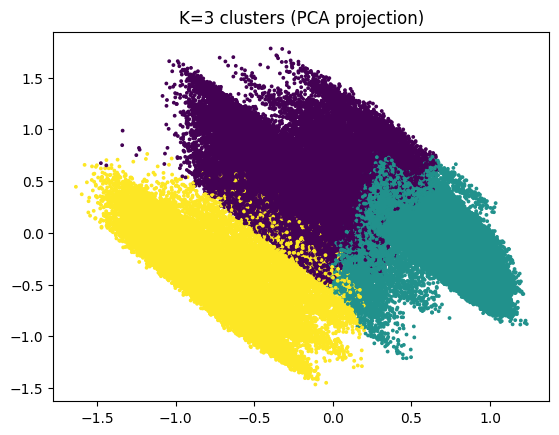

In [72]:
km = KMeans(n_clusters=3, random_state=42, n_init=10)
df_prof = df.copy()
df_prof['cluster'] = km.fit_predict(X_cluster)

# mean of every feature per cluster
profile = df_prof.groupby('cluster').mean(numeric_only=True).T
display(profile.round(2))

# share of satisfied passengers per cluster
print(df_prof.groupby('cluster')['satisfaction'].mean().round(3))

# visualise on the top-2 principal components
from sklearn.decomposition import PCA
pts = PCA(n_components=2, random_state=42).fit_transform(X_cluster)
plt.scatter(pts[:,0], pts[:,1], c=df_prof['cluster'], cmap='viridis', s=3)
plt.title('K=3 clusters (PCA projection)'); plt.show()

With K = 4, the clusters are very similar to K = 3, with one extra split. The satisfied business-class group from K = 3 was divided into two clusters that are almost identical, with the same satisfaction rate (75%), the same ratings and the same travel type, differing only by gender (one cluster is all one gender and the other is all the other). The other two clusters remained similar: business travelers in lower classes with mostly disloyal customers (18% satisfied) and loyal leisure travelers in economy (10% satisfied). So the extra cluster does not reveal a new passenger profile. It only separates passengers by gender, which has no effect on satisfaction.

cluster,0,1,2,3
Gender,0.45,1.00,0.50,0.00
Customer Type,0.29,0.92,1.00,0.93
Type of Travel,1.00,0.98,0.00,0.98
Class,0.23,0.88,0.10,0.90
Flight Distance,0.17,0.40,0.19,0.41
Inflight wifi service,0.48,0.60,0.50,0.60
Departure/Arrival time convenient,0.48,0.59,0.73,0.60
Ease of Online booking,0.52,0.60,0.49,0.60
Gate location,0.59,0.60,0.58,0.60
Food and drink,0.53,0.71,0.61,0.70


cluster
0    0.180
1    0.749
2    0.102
3    0.750
Name: satisfaction, dtype: float64


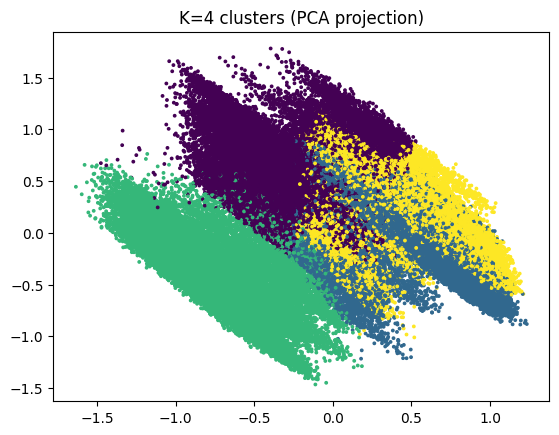

In [73]:
km = KMeans(n_clusters=4, random_state=42, n_init=10)
df_prof = df.copy()
df_prof['cluster'] = km.fit_predict(X_cluster)

# mean of every feature per cluster
profile = df_prof.groupby('cluster').mean(numeric_only=True).T
display(profile.round(2))

# share of satisfied passengers per cluster
print(df_prof.groupby('cluster')['satisfaction'].mean().round(3))

# visualise on the top-2 principal components
from sklearn.decomposition import PCA
pts = PCA(n_components=2, random_state=42).fit_transform(X_cluster)
plt.scatter(pts[:,0], pts[:,1], c=df_prof['cluster'], cmap='viridis', s=3)
plt.title('K=4 clusters (PCA projection)'); plt.show()

With K = 5, the clustering again splits passengers mostly by binary attributes, mainly gender and customer type, not by service experience. The disloyal business travelers become a clearly separate cluster (21% satisfied), and both the satisfied business-class group (77% and 76%) and the dissatisfied leisure group (11% and 16%) are each split into two clusters by gender. The satisfaction level and service ratings are nearly the same within each pair, so these splits add no new information about passenger satisfaction. The result is also harder to interpret because there are more clusters but no more meaningful differences.

cluster,0,1,2,3,4
Gender,1.00,0.45,1.00,0.00,0.00
Customer Type,1.00,0.00,0.97,1.00,0.97
Type of Travel,0.15,1.00,0.99,0.22,0.99
Class,0.10,0.36,0.88,0.09,0.95
Flight Distance,0.19,0.17,0.41,0.19,0.44
Inflight wifi service,0.49,0.52,0.60,0.52,0.58
Departure/Arrival time convenient,0.71,0.46,0.59,0.70,0.59
Ease of Online booking,0.51,0.52,0.60,0.52,0.59
Gate location,0.59,0.60,0.60,0.59,0.60
Food and drink,0.58,0.59,0.71,0.61,0.69


cluster
0    0.109
1    0.214
2    0.767
3    0.164
4    0.764
Name: satisfaction, dtype: float64


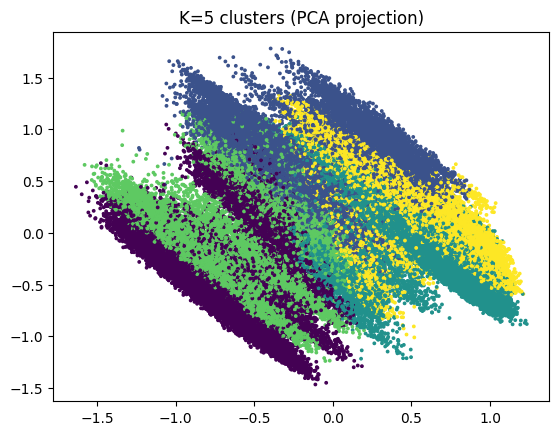

In [74]:
km = KMeans(n_clusters=5, random_state=42, n_init=10)
df_prof = df.copy()
df_prof['cluster'] = km.fit_predict(X_cluster)

# mean of every feature per cluster
profile = df_prof.groupby('cluster').mean(numeric_only=True).T
display(profile.round(2))

# share of satisfied passengers per cluster
print(df_prof.groupby('cluster')['satisfaction'].mean().round(3))

# visualise on the top-2 principal components
from sklearn.decomposition import PCA
pts = PCA(n_components=2, random_state=42).fit_transform(X_cluster)
plt.scatter(pts[:,0], pts[:,1], c=df_prof['cluster'], cmap='viridis', s=3)
plt.title('K=5 clusters (PCA projection)'); plt.show()

In both K = 4 and K = 5, the additional clusters split existing groups on attributes that do not affect satisfaction, such as gender, so K = 3 gives the clearest and most meaningful segments. This agrees with the evaluation metrics, since K = 3 has the highest silhouette width and the extra clusters at higher K lower it (0.1687 → 0.1466 → 0.1431) while WSS improves only slightly.

## 7.3 Comparison with the Research Paper


We compared our results with Hibović et al. [1], who applied several classification
algorithms to the same Airline Passenger Satisfaction dataset using R and an 80/20 split.

| | Paper (rpart, Gini) | Our model (Gini) |
|---|---|---|
| Dataset size | ~26,000 rows | 123,310 rows |
| Split | 80% / 20% | 80% / 20% |
| Tree size | Pruned, 8 splits (9 leaves) | Full depth (≈40 levels, 4,369 leaves) |
| Accuracy | 90.20% | 94.64% |

**Classification**

Our Gini decision tree achieved a higher accuracy than the paper's Gini-based tree
(94.64% vs 90.20%) on the same 80/20 split. We believe this is due to three reasons:
(1) we used almost five times more data, which gives the tree more examples to learn from;
(2) the paper used a small pruned tree, while our tree was grown to full depth, which
captures more detailed patterns; and (3) the paper removed two attributes (Gate location
and Arrival Delay), while we kept them after handling missing values.

Our accuracy is also close to the paper's entropy-based C5.0 tree (95.02%), which shows
that both attribute selection measures perform similarly on this dataset. In the paper,
Online boarding was the most important attribute in the Gini tree, followed by Inflight
wifi service, which supports the importance of digital services for passenger satisfaction.



**Clustering.**

The paper does not use clustering, but its exploratory analysis supports our clusters. It found that satisfaction is much higher in Business class (0.695) than in Eco (0.194) and Eco Plus (0.248), higher for loyal (0.477) than disloyal customers (0.248), and unrelated to gender (0.443 vs. 0.435). Our K = 3 clusters show the same pattern: the 85%-satisfied cluster is almost entirely business class, the two dissatisfied clusters are mostly economy, and at K = 4 and K = 5 the clusters that split by gender have identical satisfaction rates. Our clusters add one detail: loyal leisure travelers (Cluster 2, 10% satisfied) are less satisfied than disloyal business travelers (21% at K = 5), so travel type and class matter more than loyalty alone. This also relates to the limitation the paper raises about the unknown criteria behind the Loyal/Disloyal label.
Differences in method. The paper used R, median/mode imputation and 10-fold cross-validation for KNN, whereas we used Python and holdout partitions of 90/10, 80/20 and 70/30. Even so, both studies reached similar accuracy, which suggests the dataset’s signal is strong enough that the choice of tool matters little.


# [8] References

[1] L. Hibović, S. Smajić, and E. Yaman, "Predicting Satisfaction of Airline Passengers Using Classification," in *Proc. 2022 International Symposium on Multidisciplinary Studies and Innovative Technologies (ISMSIT)*, 2022, doi: 10.1109/ISMSIT56059.2022.9932850.

[2] T. J. Klein, "Airline Passenger Satisfaction," Kaggle. [Online]. Available: https://www.kaggle.com/datasets/teejmahal20/airline-passenger-satisfaction
[Accessed: Nov. 2026].

[3] J. Han, M. Kamber, and J. Pei, *Data Mining: Concepts and Techniques*, 3rd ed. Morgan Kaufmann, 2011.

[4] F. Pedregosa et al., "Scikit-learn: Machine Learning in Python," *Journal of Machine Learning Research*, vol. 12, pp. 2825–2830, 2011.